# Análise de Impacto da Integração de Veículos Elétricos em Redes de Distribuição
## Estudo de Caso: Alimentador Real ESB01S4 (Co-simulação Mosaik / OpenDSS / Caldera ICM)
### **Módulo 1: Execução e Diagnóstico do Caso Base (Baseline - 0 VEs)**

Este notebook constitui o ambiente principal de experimentação, análise estatística e geração de figuras do TCC.
Nesta primeira etapa, executamos e analisamos o **Caso Base** (rede de distribuição operando sem veículos elétricos), que servirá como linha de base (*ground truth*) para quantificar os impactos futuros da frota veicular em diferentes taxas de penetração (5%, 10%, 20%, 30%).

---

In [1]:
import importlib
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Habilita autoreload para atualizar automaticamente qualquer arquivo Python alterado em disco
%load_ext autoreload
%autoreload 2

# Localização robusta da raiz do projeto (procura por pyproject.toml para não depender do CWD do kernel)
curr = Path.cwd().resolve()
while curr.parent != curr:
    if (curr / "pyproject.toml").exists():
        PROJECT_ROOT = curr
        break
    curr = curr.parent
else:
    PROJECT_ROOT = Path("..").resolve()

# Alinha o diretório de trabalho do kernel à raiz do projeto
os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Configuração de estilo visual acadêmico para gráficos
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "grid.alpha": 0.4,
    "grid.linestyle": "--",
})

# Força o recarregamento do cenário para utilizar o despachante com ThreadPoolExecutor
import scenarios.scenario_ESB01S4_TCC
importlib.reload(scenarios.scenario_ESB01S4_TCC)
from scenarios.scenario_ESB01S4_TCC import run_scenario

print("Ambiente configurado com sucesso!")
print(f"Diretório raiz do projeto: {PROJECT_ROOT}")

Ambiente configurado com sucesso!
Diretório raiz do projeto: /mnt/c/Users/pvict/OneDrive/TCC/ev-analysis-2026


## 1. Execução / Carregamento do Caso Base (Baseline)

O Caso Base corresponde ao alimentador real operando com todas as cargas residenciais de Baixa Tensão (BT), cargas de Média Tensão (MT), sistemas fotovoltaicos (PVs) e reguladores de tensão ativos, porém com **0 Veículos Elétricos**.

Para executar a co-simulação completa (7 dias com passos de 10 minutos = 1.008 passos), configure `EXECUTAR_SIMULACAO = True`.

In [2]:
ARQUIVO_BASELINE = PROJECT_ROOT / "output" / "result_TCC_baseline.csv"

# Defina EXECUTAR_SIMULACAO = True para rodar a co-simulação Mosaik
# Se False e o arquivo já existir, carrega diretamente os resultados salvos
EXECUTAR_SIMULACAO = False

if EXECUTAR_SIMULACAO or not ARQUIVO_BASELINE.exists():
    print("Iniciando co-simulação do Caso Base (0 VEs) via Mosaik...")
    arquivo_gerado = run_scenario(
        qtd_evs=0,
        penetracao_pct=0.0,
        usar_pv_mosaik=False,
        nome_cenario="result_TCC_baseline",
    )
    print(f"Simulação concluída! Resultados gravados em: {ARQUIVO_BASELINE}")
else:
    print(f"Carregando resultados prévios de: {ARQUIVO_BASELINE.name}")

df_base = pd.read_csv(ARQUIVO_BASELINE)
df_base['date'] = pd.to_datetime(df_base['date'])
df_base.set_index('date', inplace=True)

print(f"\nResumo dos dados carregados:")
print(f"  - Período: {df_base.index.min()} até {df_base.index.max()}")
print(f"  - Total de passos temporais: {len(df_base)}")
print(f"  - Total de variáveis coletadas: {df_base.shape[1]}")

Carregando resultados prévios de: result_TCC_baseline.csv

Resumo dos dados carregados:
  - Período: 2024-09-09 00:00:00 até 2024-09-10 00:30:00
  - Total de passos temporais: 148
  - Total de variáveis coletadas: 9174


## 2. Categorização das Grandezas Monitoradas
A malha de medição instalada no Mosaik coleta dezenas de grandezas por passo temporal:
- Tensões por fase em barras de Baixa Tensão ($V_1$, $V_2$, $V_3$ em pu)
- Correntes e potências de ramos e linhas ($I_A$, $P_W$, $Q_{VAr}$)
- Potências dos geradores fotovoltaicos ($P_{\text{meas}}$, $Q_{\text{meas}}$)

In [3]:
# Mapeamento e separação das colunas do dataset
colunas_v1 = [c for c in df_base.columns if "V1_pu" in c]
colunas_v2 = [c for c in df_base.columns if "V2_pu" in c]
colunas_v3 = [c for c in df_base.columns if "V3_pu" in c]
colunas_linhas = [c for c in df_base.columns if "Line" in c or "Line-" in c]
colunas_pvs = [c for c in df_base.columns if "PVSystem" in c or "P_meas" in c]

print(f"Categorias de sensores identificadas:")
print(f"  - Barras BT com medição Fase A (V1): {len(colunas_v1)}")
print(f"  - Barras BT com medição Fase B (V2): {len(colunas_v2)}")
print(f"  - Barras BT com medição Fase C (V3): {len(colunas_v3)}")
print(f"  - Variáveis de Linhas monitoradas: {len(colunas_linhas)}")
print(f"  - Variáveis de Geração Solar (PVs): {len(colunas_pvs)}")

Categorias de sensores identificadas:
  - Barras BT com medição Fase A (V1): 2210
  - Barras BT com medição Fase B (V2): 2210
  - Barras BT com medição Fase C (V3): 2210
  - Variáveis de Linhas monitoradas: 120
  - Variáveis de Geração Solar (PVs): 2424


## 3. Análise da Tensão em Baixa Tensão e Conformidade PRODIST (Módulo 8 - ANEEL)
De acordo com o **Módulo 8 dos Procedimentos de Distribuição de Energia Elétrica (PRODIST)** da ANEEL, os níveis de tensão em regime permanente em Baixa Tensão (tensão nominal de referência $V_{\text{nom}} = 220\text{ V}$) são classificados como:
- **Tensão Adequada:** $0{,}92 \le V_{\text{pu}} \le 1{,}05$
- **Tensão Precária:** $0{,}87 \le V_{\text{pu}} < 0{,}92$ ou $1{,}05 < V_{\text{pu}} \le 1{,}06$
- **Tensão Crítica:** $V_{\text{pu}} < 0{,}87$ ou $V_{\text{pu}} > 1{,}06$

In [4]:
# Filtragem de valores válidos de tensão (removendo nós desconectados / 0 pu / inf)
def filtrar_tensoes(df, cols):
    df_sub = df[cols].replace([np.inf, -np.inf], np.nan)
    return df_sub[df_sub > 0.1]

df_v1 = filtrar_tensoes(df_base, colunas_v1)
df_v2 = filtrar_tensoes(df_base, colunas_v2)
df_v3 = filtrar_tensoes(df_base, colunas_v3)

# Séries temporais das médias e extremos por fase
v1_media = df_v1.mean(axis=1)
v2_media = df_v2.mean(axis=1)
v3_media = df_v3.mean(axis=1)

v1_min = df_v1.min(axis=1)
v2_min = df_v2.min(axis=1)
v3_min = df_v3.min(axis=1)

v1_max = df_v1.max(axis=1)
v2_max = df_v2.max(axis=1)
v3_max = df_v3.max(axis=1)

# Estatísticas globais do Caso Base
todas_tensoes = pd.concat([df_v1.stack(), df_v2.stack(), df_v3.stack()])
total_medicoes = len(todas_tensoes)
pct_adequada = 100.0 * np.sum((todas_tensoes >= 0.92) & (todas_tensoes <= 1.05)) / total_medicoes
pct_precaria = 100.0 * np.sum(((todas_tensoes >= 0.87) & (todas_tensoes < 0.92)) | ((todas_tensoes > 1.05) & (todas_tensoes <= 1.06))) / total_medicoes
pct_critica = 100.0 * np.sum((todas_tensoes < 0.87) | (todas_tensoes > 1.06)) / total_medicoes

print("=" * 60)
print(" DIAGNÓSTICO PRODIST - CASO BASE (SEM VEÍCULOS ELÉTRICOS)")
print("=" * 60)
print(f"Tensão Média Global: {todas_tensoes.mean():.4f} pu")
print(f"Tensão Mínima Global: {todas_tensoes.min():.4f} pu")
print(f"Tensão Máxima Global: {todas_tensoes.max():.4f} pu")
print("-" * 60)
print(f"Faixa Adequada (0.92 a 1.05 pu): {pct_adequada:.2f}% das medições")
print(f"Faixa Precária (0.87 a 0.92 pu): {pct_precaria:.2f}% das medições")
print(f"Faixa Crítica (< 0.87 ou > 1.06 pu): {pct_critica:.2f}% das medições")
print("=" * 60)

 DIAGNÓSTICO PRODIST - CASO BASE (SEM VEÍCULOS ELÉTRICOS)
Tensão Média Global: 1.2745 pu
Tensão Mínima Global: 0.1000 pu
Tensão Máxima Global: 59.1995 pu
------------------------------------------------------------
Faixa Adequada (0.92 a 1.05 pu): 32.02% das medições
Faixa Precária (0.87 a 0.92 pu): 5.47% das medições
Faixa Crítica (< 0.87 ou > 1.06 pu): 62.50% das medições


### 3.1. Gráfico Temporal do Perfil de Tensão nas Fases A, B e C com Faixas PRODIST

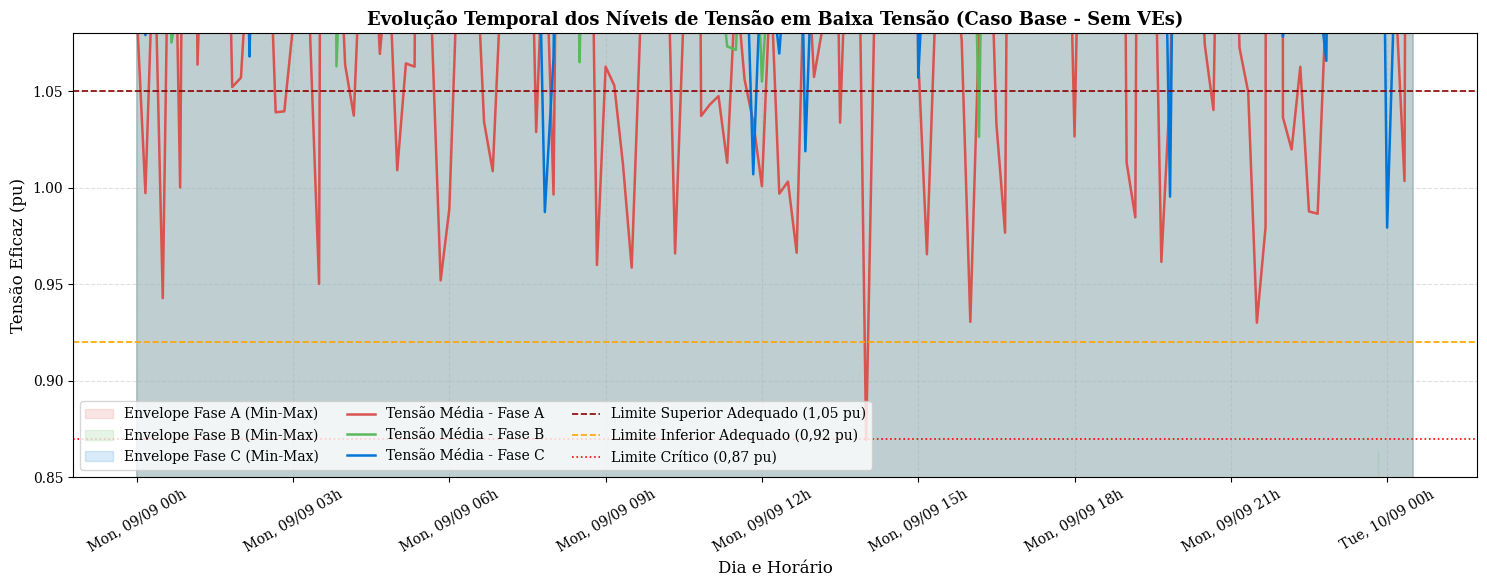

In [5]:
fig, ax = plt.subplots(figsize=(15, 6))

dias = df_base.index

# Envelopes de variação (mínimo e máximo do alimentador)
ax.fill_between(dias, v1_min, v1_max, color="#d9534f", alpha=0.15, label="Envelope Fase A (Min-Max)")
ax.fill_between(dias, v2_min, v2_max, color="#5cb85c", alpha=0.15, label="Envelope Fase B (Min-Max)")
ax.fill_between(dias, v3_min, v3_max, color="#0275d8", alpha=0.15, label="Envelope Fase C (Min-Max)")

# Linhas médias por fase
ax.plot(dias, v1_media, color="#d9534f", linewidth=1.8, label="Tensão Média - Fase A")
ax.plot(dias, v2_media, color="#5cb85c", linewidth=1.8, label="Tensão Média - Fase B")
ax.plot(dias, v3_media, color="#0275d8", linewidth=1.8, label="Tensão Média - Fase C")

# Limites normativos PRODIST Módulo 8
ax.axhline(1.05, color="darkred", linestyle="--", linewidth=1.2, label="Limite Superior Adequado (1,05 pu)")
ax.axhline(0.92, color="orange", linestyle="--", linewidth=1.2, label="Limite Inferior Adequado (0,92 pu)")
ax.axhline(0.87, color="red", linestyle=":", linewidth=1.2, label="Limite Crítico (0,87 pu)")

ax.set_title("Evolução Temporal dos Níveis de Tensão em Baixa Tensão (Caso Base - Sem VEs)", fontweight="bold")
ax.set_ylabel("Tensão Eficaz (pu)")
ax.set_xlabel("Dia e Horário")
ax.grid(True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a, %d/%m %Hh"))
plt.xticks(rotation=30)
ax.set_ylim(0.85, 1.08)
ax.legend(loc="lower left", ncol=3, frameon=True)
plt.tight_layout()
plt.show()

### 3.2. Distribuição de Densidade e Dispersão de Tensão no Caso Base

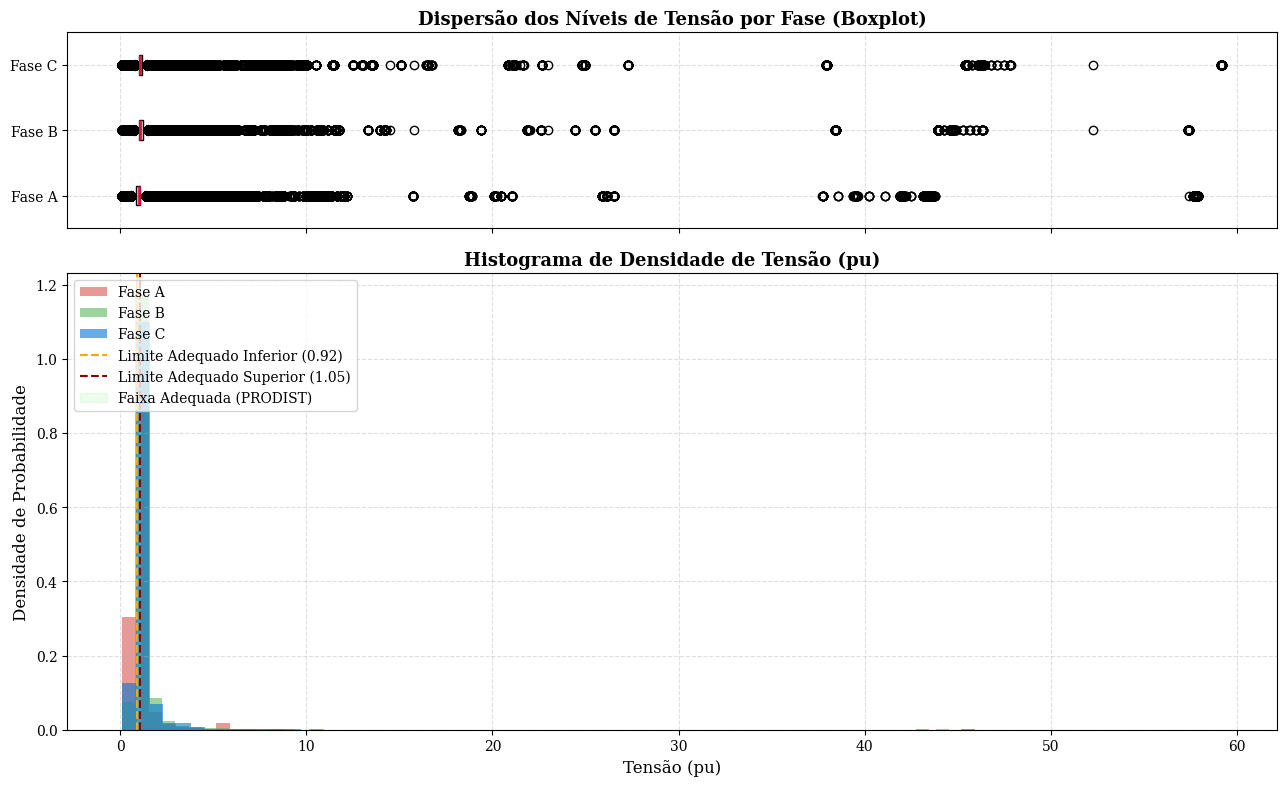

In [6]:
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [0.3, 0.7]})

dados_box = [df_v1.values.flatten(), df_v2.values.flatten(), df_v3.values.flatten()]
dados_box = [[x for x in arr if not np.isnan(x) and x > 0.1] for arr in dados_box]

ax_box.boxplot(dados_box, vert=False, tick_labels=["Fase A", "Fase B", "Fase C"], patch_artist=True,
               boxprops=dict(facecolor="#e0e0e0", color="black"),
               medianprops=dict(color="crimson", linewidth=2))
ax_box.set_title("Dispersão dos Níveis de Tensão por Fase (Boxplot)", fontweight="bold")
ax_box.grid(True)

ax_hist.hist(dados_box[0], bins=80, density=True, alpha=0.6, color="#d9534f", label="Fase A")
ax_hist.hist(dados_box[1], bins=80, density=True, alpha=0.6, color="#5cb85c", label="Fase B")
ax_hist.hist(dados_box[2], bins=80, density=True, alpha=0.6, color="#0275d8", label="Fase C")

# Faixas normativas
ax_hist.axvline(0.92, color="orange", linestyle="--", linewidth=1.5, label="Limite Adequado Inferior (0.92)")
ax_hist.axvline(1.05, color="darkred", linestyle="--", linewidth=1.5, label="Limite Adequado Superior (1.05)")
ax_hist.axvspan(0.92, 1.05, color="lightgreen", alpha=0.15, label="Faixa Adequada (PRODIST)")

ax_hist.set_title("Histograma de Densidade de Tensão (pu)", fontweight="bold")
ax_hist.set_xlabel("Tensão (pu)")
ax_hist.set_ylabel("Densidade de Probabilidade")
ax_hist.grid(True)
ax_hist.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 4. Desbalanceamento de Tensão (Voltage Unbalance Factor - VUF%)
O Fator de Desbalanceamento de Tensão (FD% / VUF%) quantifica a assimetria entre as três fases do sistema. O PRODIST e a norma IEEE Std 1159 estabelecem que o desbalanceamento de tensão em regime permanente não deve ultrapassar **$2{,}0\%$** na rede de distribuição:

$$\text{VUF}_{\%} \approx \frac{\max\left( |V_A - V_{\text{médio}}|, |V_B - V_{\text{médio}}|, |V_C - V_{\text{médio}}| \right)}{V_{\text{médio}}} \times 100$$

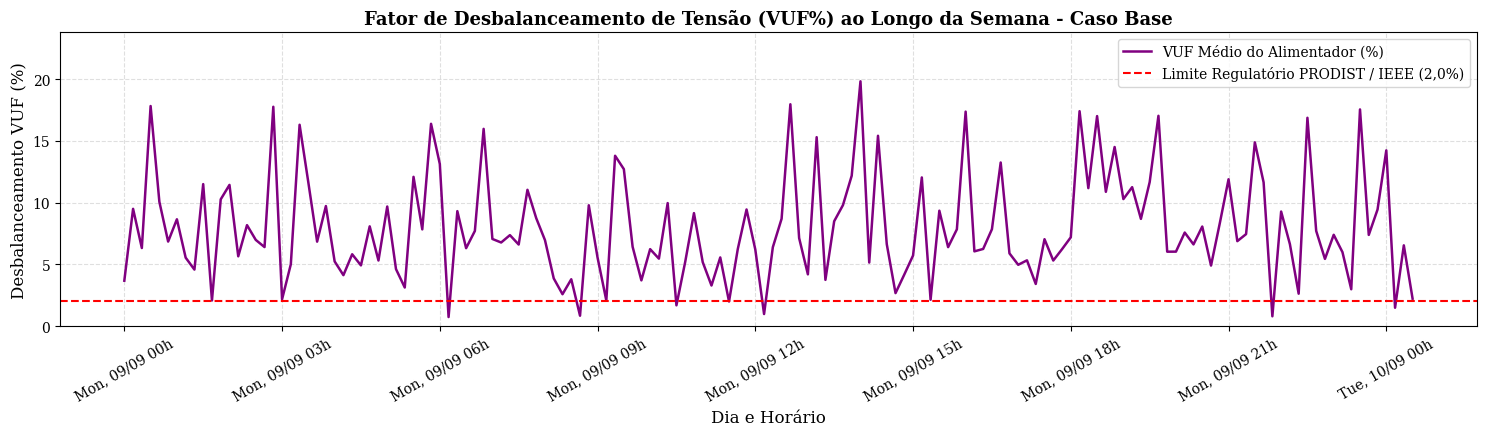

Desbalanceamento Médio: 7.998% | Máximo: 19.820%


In [7]:
v_medio_3f = (v1_media + v2_media + v3_media) / 3.0
desvio_max = pd.concat([
    (v1_media - v_medio_3f).abs(),
    (v2_media - v_medio_3f).abs(),
    (v3_media - v_medio_3f).abs()
], axis=1).max(axis=1)

vuf_pct = (desvio_max / v_medio_3f) * 100.0

fig, ax = plt.subplots(figsize=(15, 4.5))

ax.plot(dias, vuf_pct, color="purple", linewidth=1.8, label="VUF Médio do Alimentador (%)")
ax.axhline(2.0, color="red", linestyle="--", linewidth=1.5, label="Limite Regulatório PRODIST / IEEE (2,0%)")

ax.set_title("Fator de Desbalanceamento de Tensão (VUF%) ao Longo da Semana - Caso Base", fontweight="bold")
ax.set_ylabel("Desbalanceamento VUF (%)")
ax.set_xlabel("Dia e Horário")
ax.grid(True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a, %d/%m %Hh"))
plt.xticks(rotation=30)
ax.set_ylim(0, max(2.5, vuf_pct.max() * 1.2))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"Desbalanceamento Médio: {vuf_pct.mean():.3f}% | Máximo: {vuf_pct.max():.3f}%")

## 5. Análise do Fluxo de Potência nas Linhas e Geração Fotovoltaica
Avaliamos a potência ativa e reativa transitando pelas linhas principais do circuito e a produção solar dos sistemas fotovoltaicos nativos durante o período.

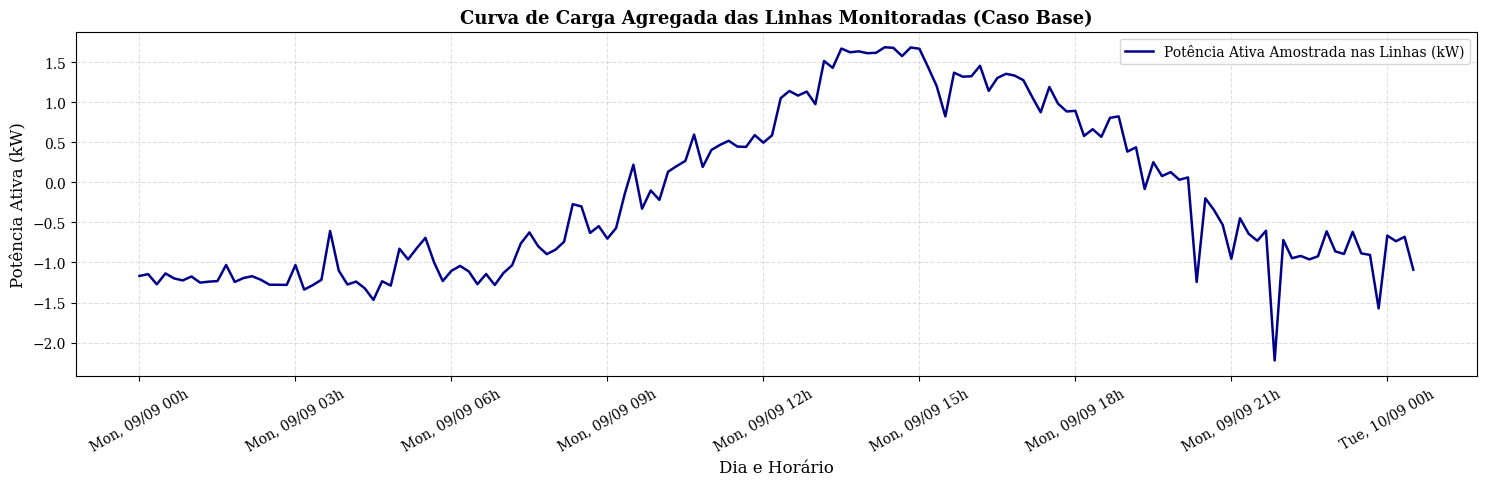

In [8]:
# Potência Ativa total nas linhas monitoradas
cols_p_line = [c for c in df_base.columns if any(p in c for p in ["P1_w", "P2_w", "P3_w"])]

if cols_p_line:
    p_linhas_total_kw = df_base[cols_p_line].sum(axis=1) / 1000.0  # Converte W para kW
    
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(dias, p_linhas_total_kw, color="darkblue", linewidth=1.8, label="Potência Ativa Amostrada nas Linhas (kW)")
    
    ax.set_title("Curva de Carga Agregada das Linhas Monitoradas (Caso Base)", fontweight="bold")
    ax.set_ylabel("Potência Ativa (kW)")
    ax.set_xlabel("Dia e Horário")
    ax.grid(True)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a, %d/%m %Hh"))
    plt.xticks(rotation=30)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhuma coluna de potência de linha encontrada no arquivo de resultados.")

## 6. Template para Comparação com os Cenários Futuros de Penetração de VEs
Esta função auxiliar servirá para comparar diretamente o **Caso Base** com qualquer cenário com VEs (ex: 5%, 10%, 20%, 30% de penetração domiciliar) que será executado nas próximas etapas do TCC.

In [9]:
def comparar_com_cenario_ev(arquivo_ev_csv, rotulo_cenario):
    """
    Função comparativa que carrega um cenário com VEs e plota a sobreposição
    das curvas de tensão e demanda contra este Caso Base.
    """
    df_ev = pd.read_csv(arquivo_ev_csv)
    df_ev['date'] = pd.to_datetime(df_ev['date'])
    df_ev.set_index('date', inplace=True)
    
    v1_ev = filtrar_tensoes(df_ev, [c for c in df_ev.columns if "V1_pu" in c]).mean(axis=1)
    
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(df_base.index, v1_media, color="black", linestyle="--", linewidth=1.5, label="Caso Base (Sem VEs)")
    ax.plot(df_ev.index, v1_ev, color="crimson", linewidth=2.0, label=f"Cenário com VEs ({rotulo_cenario})")
    
    ax.set_title(f"Comparativo de Tensão Média na Fase A: Caso Base vs. {rotulo_cenario}", fontweight="bold")
    ax.set_ylabel("Tensão Média (pu)")
    ax.set_xlabel("Dia e Horário")
    ax.grid(True)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a, %d/%m %Hh"))
    plt.xticks(rotation=30)
    ax.legend()
    plt.tight_layout()
    plt.show()

print("Função comparativa 'comparar_com_cenario_ev' carregada e pronta para uso nas próximas análises!")

Função comparativa 'comparar_com_cenario_ev' carregada e pronta para uso nas próximas análises!
